# Estimating the Fundamental Matrix

In [29]:
import numpy as np
import cv2 as cv
import scipy.io
import sys
from matplotlib import pyplot as plt

#Auxiliary Functions

In [30]:

# Estimate Fundamental Matrix
def estimate_fundamental (ptsl, ptsr):
  npts = ptsl.shape[1]

  # Fundamental Matrix Estimation
  # A_nx9.Fs_9x1 = 0

  # Assemble matrix A
  # Calculate matrix Ai for each corresponding pair of points using the Kronecker Product
  # Stack the equation for each pair of matchings

  A = np.zeros((npts, 9))

  for i in range(npts):
    A[i,:] = np.kron(ptsr[:, i],ptsl[:, i])

  # Compute the SVD of matrix A

  Ua, Sa, Vat = np.linalg.svd(A)

  # Pick the singular vector corresponding to the smallest singular valeu
  # Define the first estimation for the Fundamental matrix
  F1 = Vat[-1,:].reshape(3,3)


  # Compute the SVD of the first estimation of the Fundamental Matrix
  U, S, Vt = np.linalg.svd(F1)
  S[-1] = 0

  # Substitute the diagonal matrix to project the first estimation into the
  # Fundamental Matrix Space/Domain
  # Compute the new Fundamental Matrix belonging to the right domain

  F = U @ np.diag(S) @ Vt

  return F/F[2,2]


def estimate_normalized_fundamental (ptsl, ptsr):

    ptsl_n, Tl = normalize(ptsl)
    ptsr_n, Tr = normalize(ptsr)
    # Estimate essential matrix
    F = estimate_fundamental (ptsl_n, ptsr_n)
    # reverse normalization
    F = np.dot(Tr.T,np.dot(F,Tl))

    return F/F[2,2]

# Normalize the points
def normalize(pts):

    # to be sure that the last line is all of ones - homogeneous coordinates
    pts = pts / pts[2]

    npoints = pts.shape[1] # number of columns
    # Calculate the Centroid
    #centx = np.sum (pts[0,:])/npoints
    #centy = np.sum (pts[1,:])/npoints
    centroid = np.mean(pts[:2],axis=1)
    # Calculation of the  mean distance in relation to the centroid
    dist_med = sum(np.sqrt((pts[0,:] - centroid[0])**2 + (pts[1,:] - centroid[1])**2))/npoints
    # Scale to make the mean distance equal to  sqrt(2)
    esc = np.sqrt(2)/dist_med
    esc = np.sqrt(2)/np.std(pts[:2])
    # Normalization matrix
    T = np.array([[esc, 0, -esc*centroid[0]],[0, esc, -esc*centroid[1]],[ 0, 0, 1]])

    #Normalized points
    pts_norm = np.dot(T,pts)

    return pts_norm,T


def plot_epipolar_line(im,F,x,xx):

  # Plot the epipolar line F*x in an image. F is the fundamental matrix,
  # x a point in the other image and xx a point in the image where the
  # epipolar line will be plotted.

  m,n = im.shape[:2]
  line = np.dot(F,x)

  # epipolar line parameter and values
  t = np.linspace(0,n,100)
  lt = np.array([(line[2]+line[0]*tt)/(-line[1]) for tt in t])

  # take only line points inside the image
  ndx = (lt>=0) & (lt<m)
  plt.plot(t[ndx],lt[ndx],linewidth=1)
  plt.plot(xx[0],xx[1],'o')






#Example Cases

In [31]:
def case_one():
    # Read images
    img1 = cv.imread('boxes1.bmp') #left image
    img2 = cv.imread('boxes8.bmp') #right image

    img_left = cv.cvtColor(img1,cv.COLOR_BGR2RGB)
    img_right = cv.cvtColor(img2,cv.COLOR_BGR2RGB)


    # Read points that were collected manually
    data = scipy.io.loadmat('boxpoints.mat')

    xim = data['xim']

    pts_left = xim[:,:,0]
    pts_right = xim[:,:,1]


    return img_left,img_right,pts_left,pts_right

def case_two():
    # Read images
    img1 = cv.imread('001.jpg') #left image
    img2 = cv.imread('002.jpg') #right image

    img_left = cv.cvtColor(img1,cv.COLOR_BGR2RGB)
    img_right = cv.cvtColor(img2,cv.COLOR_BGR2RGB)


    # Read points from file
    points2D = [np.loadtxt('00'+str(i+1)+'.corners').T for i in range(2)]
    # load correspondences
    corr = np.genfromtxt('nview-corners',dtype='int',missing_values='*')

    # index for points in first two views
    ndx = (corr[:,0]>=0) & (corr[:,1]>=0)
    # get coordinates and make homogeneous
    pts_left = points2D[0][:,corr[ndx,0]]
    pts_left = np.vstack( (pts_left,np.ones(pts_left.shape[1])) )
    pts_right = points2D[1][:,corr[ndx,1]]
    pts_right = np.vstack( (pts_right,np.ones(pts_right.shape[1])) )

    return img_left,img_right,pts_left,pts_right

def case_three():
    #Read images
    imgl = cv.imread('colorLeft.png')  #queryimage # left image
    imgr = cv.imread('colorRight.png') #trainimage # right image

    # find the keypoints and descriptors with SIFT
    sift = cv.SIFT_create()
    kp1, des1 = sift.detectAndCompute(imgl,None)
    kp2, des2 = sift.detectAndCompute(imgr,None)

    # Solve matching between detected points in both images
    # FLANN parameters
    FLANN_INDEX_KDTREE = 1
    index_params = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
    search_params = dict(checks=50)
    flann = cv.FlannBasedMatcher(index_params,search_params)
    matches = flann.knnMatch(des1,des2,k=2)
    good = []
    ptsl = []
    ptsr = []

    # Select good matches
    # ratio test as per Lowe's paper
    for i,(m,n) in enumerate(matches):

        if m.distance < 0.8*n.distance:
            good.append(m)
            ptsr.append(kp2[m.trainIdx].pt)
            ptsl.append(kp1[m.queryIdx].pt)


    ptsl = np.int32(ptsl).T
    ptsr = np.int32(ptsr).T
    ptsl = np.vstack( (ptsl,np.ones(ptsl.shape[1])) )
    ptsr = np.vstack( (ptsr,np.ones(ptsr.shape[1])) )

    return imgl,imgr,ptsl,ptsr

#Main


Fundamental Matrix obtained with OpenCV function: 
 F = 
 [[ 1.89426364e-06 -1.33755395e-04  1.28784934e-02]
 [ 1.49613734e-04  2.80491198e-06 -2.70367996e-01]
 [-1.78976842e-02  2.56903274e-01  1.00000000e+00]]

Fundamental Matrix obtained with my function: 
 F = 
 [[-1.08724444e-05  4.25293460e-04 -1.18970872e-02]
 [-4.32549993e-04  4.24169142e-05  3.26656919e-01]
 [ 1.86977232e-02 -3.20835984e-01  1.00000000e+00]]


(np.float64(-0.5),
 np.float64(672.025),
 np.float64(503.86196068163633),
 np.float64(-0.5))

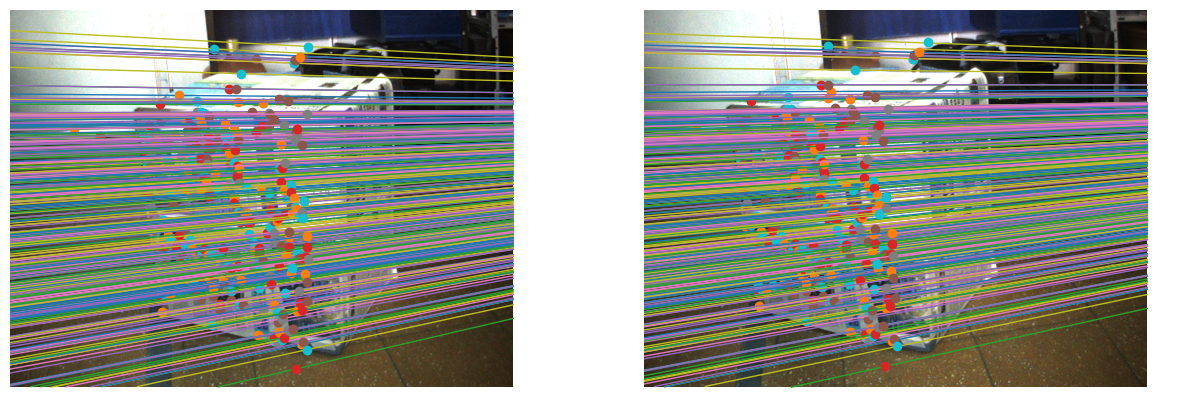

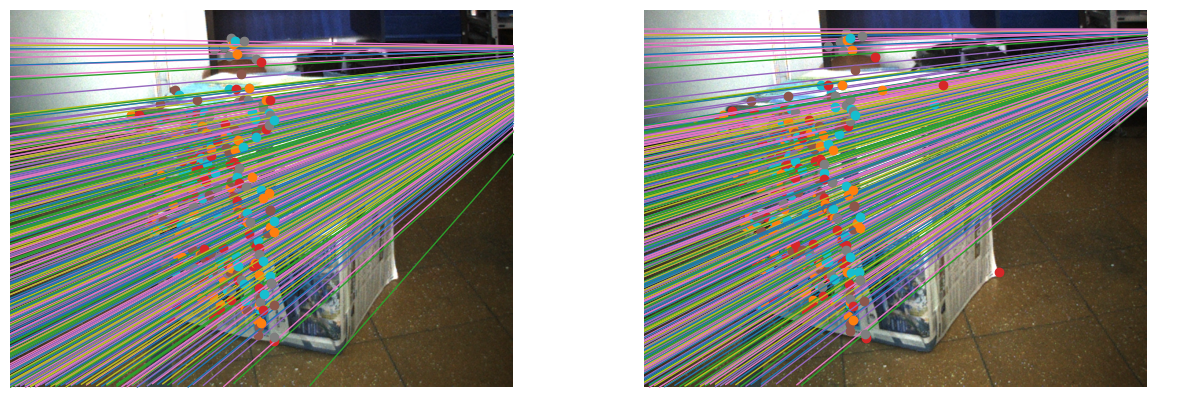

In [36]:
CASE = 3

if CASE == 1:
    img_left,img_right,pts_left,pts_right = case_one()
    n_epilines = pts_left.shape[1]

if CASE == 2:
    img_left,img_right,pts_left,pts_right = case_two()
    n_epilines = 40

if CASE == 3:
    img_left,img_right,pts_left,pts_right = case_three()
    n_epilines = 400


# Using OpenCV to estimate the Fundamental Matrix

pts1 = pts_left[0:2,:].T
pts2 = pts_right[0:2,:].T

#F2, mask = cv.findFundamentalMat(pts1,pts2,cv.FM_8POINT) #FM_8POINT
F2, mask = cv.findFundamentalMat(pts1,pts2,cv.RANSAC,1,0.9999999)
# F2 = estimate_normalized_fundamental (pts1, pts2)

print('\nFundamental Matrix obtained with OpenCV function: \n F = \n',F2)

# We select only inlier points
pts1 = pts1[mask.ravel()==1].T
pts1 = np.vstack((pts1,np.ones(pts1.shape[1])))
pts2 = pts2[mask.ravel()==1].T
pts2 = np.vstack((pts2,np.ones(pts2.shape[1])))

if pts1.shape[1]< n_epilines:
  n_epilines= pts1.shape[1]

# plotting
plt.figure(figsize=(15,8))
plt.subplot(121)
plt.imshow(img_left)

# plot each line and point individually
for i in range(n_epilines):
    plot_epipolar_line(img_left,F2.T,pts2[:,i],pts1[:,i])
    #plt.plot(pts1[0,i],pts1[1,i],'o')
plt.axis('off')

plt.subplot(122)
plt.imshow(img_right)

# plot each line and point individually
for i in range(n_epilines):
    plot_epipolar_line(img_right,F2,pts1[:,i],pts2[:,i])
    #plt.plot(pts2[0,i],pts2[1,i],'o')
plt.axis('off')


###########################################################################
# Now use the code above as an example to:
# - Use your function to estimate the Fundamental Matrix.
# - Plot the points and epipolar lines on both images

pts1 = pts_left
pts2 = pts_right

F = estimate_normalized_fundamental (pts1, pts2)

print('\nFundamental Matrix obtained with my function: \n F = \n', F)

n_epilines = 400

if pts1.shape[1]< n_epilines:
  n_epilines= pts1.shape[1]

# plotting
plt.figure(figsize=(15,8))
plt.subplot(121)
plt.imshow(img_left)

# plot each line and point individually
for i in range(n_epilines):
    plot_epipolar_line(img_left,F.T,pts2[:,i],pts1[:,i])
    #plt.plot(pts1[0,i],pts1[1,i],'o')
plt.axis('off')

plt.subplot(122)
plt.imshow(img_right)

# plot each line and point individually
for i in range(n_epilines):
    plot_epipolar_line(img_right,F,pts1[:,i],pts2[:,i])
    #plt.plot(pts2[0,i],pts2[1,i],'o')
plt.axis('off')




